# MLM Representation Sensitivity

- **Purpose:** Test whether the MLM concordance depends on the expression representation.
- **Inputs:** Shared artifact; joint model; cleaned Hallmark GMT; corrected-expression cache.
- **Outputs:** Sensitivity tables and figures under `models/validation/bio_joint_cfg10/de_signatures/hallmark_mlm_sensitivity/` and `figures/BIOVAL/`.
- **Result:** Concordance and domain-shift patterns are stable across corrected HVG, uncorrected HVG, and full-gene representations; the full-gene MLM is retained.


In [1]:
from pathlib import Path
import json
import hashlib
import sys

import anndata as ad
import numpy as np
import pandas as pd
import scvi
import decoupler as dc
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from sklearn.neighbors import NearestNeighbors

SEED = 0

def set_seed(seed):
    scvi.settings.seed = seed
    np.random.seed(seed)

set_seed(SEED)

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FIG_DIR = ROOT / "figures" / "BIOVAL"
FIG_DIR.mkdir(parents=True, exist_ok=True)

from src.utils import load_config

INPUT = Path.cwd() / "adata_config10_joint" / "config10_joint_3k.h5ad"
HALLMARK_GMT = ROOT / "data" / "Gene_sets" / "h_cleaned.all.v2023.1.Hs.symbols.gmt"

MLM_TMIN = 15
MLM_RAW = False
MLM_LIBRARY_SIZE = 1e4
K_MATCHING = 50

Seed set to 0


# Matching groups

In [2]:
combined_full = ad.read_h5ad(INPUT)
settings = combined_full.uns["bio_leiden_settings"]
TUMOR_RES = float(settings["tumor_res"])
t_key = f"tumor_leiden_res{TUMOR_RES}"

cfg = load_config()
DE_APPROACH = settings["approach"]
DE_CONFIG_ID = int(settings["config_id"])
DE_NUM_HVG = int(settings["num_hvg"])
DE_DIR = (ROOT / cfg["paths"]["models"] / "validation"
          / f"bio_{DE_APPROACH}_cfg{DE_CONFIG_ID:02d}" / "de_signatures")
MLM_PRIMARY_ARTIFACT = DE_DIR / "hallmark_mlm" / "hallmark_mlm_scores.h5ad"
MLM_SENS_DIR = DE_DIR / "hallmark_mlm_sensitivity"
MLM_SENS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Input: {INPUT}")
print(f"Shape: {combined_full.shape}")
print(f"Primary MLM artifact: {MLM_PRIMARY_ARTIFACT}")

tumor_mask = combined_full.obs["dataset"].eq("tumor")
line_mask = combined_full.obs["dataset"].eq("cell_line")

match_group = pd.Series(pd.NA, index=combined_full.obs.index, dtype="string", name="match_group")
match_group.loc[tumor_mask] = "tumor_" + combined_full.obs.loc[tumor_mask, t_key].astype("string")
match_group.loc[line_mask] = "line_" + combined_full.obs.loc[line_mask, "cell_line"].astype("string")
combined_full.obs["match_group"] = match_group


def tumor_group_sort_key(group):
    return int(str(group).rsplit("_", 1)[-1])


def tumor_knn_composition(adata, k):
    tumor_mask = adata.obs["dataset"].eq("tumor")
    line_mask = adata.obs["dataset"].eq("cell_line")

    latent = adata.obsm["X_latent"]
    tumor_latent = latent[tumor_mask]
    line_latent = latent[line_mask]
    tumor_groups = adata.obs.loc[tumor_mask, "match_group"].to_numpy()

    nn = NearestNeighbors(n_neighbors=k, metric="euclidean")
    nn.fit(tumor_latent)
    dist, idx = nn.kneighbors(line_latent)
    neighbor_groups = tumor_groups[idx]

    groups = sorted(pd.unique(tumor_groups), key=tumor_group_sort_key)
    composition = pd.DataFrame(
        {group: (neighbor_groups == group).mean(axis=1) for group in groups},
        index=adata.obs.index[line_mask],
    )
    composition.insert(0, "cell_line", adata.obs.loc[line_mask, "cell_line"].astype(str).to_numpy())
    composition["nearest_tumor_distance"] = dist[:, 0]

    for group in groups:
        group_mask = neighbor_groups == group
        composition[f"dist_{group}"] = np.where(
            group_mask.any(axis=1),
            np.where(group_mask, dist, np.inf).min(axis=1),
            np.nan,
        )
    return composition


cell_knn = tumor_knn_composition(combined_full, k=K_MATCHING)
tumor_groups = [column for column in cell_knn.columns if column.startswith("tumor_")]
line_composition = cell_knn.groupby("cell_line", observed=True)[tumor_groups].mean()

tumor_latent = combined_full.obsm["X_latent"][tumor_mask]
tumor_nn = NearestNeighbors(n_neighbors=2, metric="euclidean").fit(tumor_latent)
tumor_nn_dist = tumor_nn.kneighbors(tumor_latent)[0][:, 1]
proximity_baseline = float(np.quantile(tumor_nn_dist, 0.95))

line_matches = []
for cell_line, composition in line_composition.iterrows():
    ranked = composition.sort_values(ascending=False)
    primary, second = ranked.index[0], ranked.index[1]
    cells = cell_knn.loc[cell_knn["cell_line"].eq(cell_line)]
    median_nearest = cells["nearest_tumor_distance"].median()
    line_matches.append({
        "cell_line": cell_line,
        "n_cells": cells.shape[0],
        "primary_match": primary,
        "primary_frac": ranked.iloc[0],
        "second_match": second,
        "second_frac": ranked.iloc[1],
        "margin": ranked.iloc[0] - ranked.iloc[1],
        "median_dist_nearest_tumor": median_nearest,
        "low_proximity": median_nearest > proximity_baseline,
    })

line_matches = pd.DataFrame(line_matches).set_index("cell_line").sort_index()

TUMOR_ORDER = sorted(
    combined_full.obs.loc[tumor_mask, "match_group"].dropna().unique(),
    key=tumor_group_sort_key,
)
LINE_ORDER = sorted(
    line_matches.index,
    key=lambda cell_line: (
        tumor_group_sort_key(line_matches.loc[cell_line, "primary_match"]),
        -float(line_matches.loc[cell_line, "margin"]),
    ),
)

print(f"Tumor-tumor nearest-neighbor baseline (q95): {proximity_baseline:.3f}")
print(f"Tumor subpopulations: {len(TUMOR_ORDER)}; cell lines: {len(LINE_ORDER)}")
line_matches[["primary_match", "second_match", "margin", "low_proximity"]].round(3)

Input: /mnt/bigdisk/markus/CRC-scMFmap/notebooks/curr/adata_config10_joint/config10_joint_3k.h5ad
Shape: (110293, 28617)
Primary MLM artifact: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_joint_cfg10/de_signatures/hallmark_mlm/hallmark_mlm_scores.h5ad
Tumor-tumor nearest-neighbor baseline (q95): 1.631
Tumor subpopulations: 18; cell lines: 10


,primary_match,second_match,margin,low_proximity
cell_line,,,,
CCK81,tumor_5,tumor_4,0.264,False
CL34,tumor_4,tumor_5,0.027,False
HCC56,tumor_4,tumor_5,0.279,False
HT55,tumor_4,tumor_5,0.216,False
LS1034,tumor_4,tumor_3,0.073,False
LS180,tumor_4,tumor_5,0.143,False
NCIH747,tumor_5,tumor_4,0.132,False
OUMS23,tumor_6,tumor_5,0.281,True
RCM1,tumor_5,tumor_4,0.297,False


# Gene Sets

In [3]:
def read_gmt(path):
    gene_sets = {}
    with open(path) as handle:
        for line in handle:
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 3:
                continue
            term = fields[0].replace("HALLMARK_", "")
            gene_sets[term] = [gene for gene in fields[2:] if gene]
    return gene_sets


hallmark_sets = read_gmt(HALLMARK_GMT)
all_genes = set(map(str, combined_full.var_names))
hallmark_all_genes = sorted({gene for genes in hallmark_sets.values() for gene in genes} & all_genes)

hvg_mask = combined_full.var["hvg"].astype(bool)
hvg_genes = sorted(set(map(str, combined_full.var_names[hvg_mask])))
hvg_hallmark_genes = sorted(set(hvg_genes) & set(hallmark_all_genes))
assert len(hvg_hallmark_genes) == 1135


def build_network(genes):
    genes_set = set(genes)
    return pd.DataFrame([
        {"source": pathway, "target": gene, "weight": 1.0}
        for pathway, pathway_genes in hallmark_sets.items()
        for gene in sorted(set(map(str, pathway_genes)) & genes_set)
    ])


net_hvg = build_network(hvg_hallmark_genes)
net_sizes = net_hvg.groupby("source")["target"].nunique().sort_values(ascending=False)
hvg_pathways = sorted(net_sizes[net_sizes >= MLM_TMIN].index)
dropped_pathways = sorted(net_sizes[net_sizes < MLM_TMIN].index)

print(f"Hallmark genes in the combined artifact: {len(hallmark_all_genes)}")
print(f"Hallmark genes in the 3,000-HVG feature set: {len(hvg_hallmark_genes)}")
print(f"Pathways retained at tmin={MLM_TMIN}: {len(hvg_pathways)}")
print("Pathways below the size floor on the HVG set:", dropped_pathways)
display(net_sizes.loc[dropped_pathways].rename("genes_in_hvg_set"))

Hallmark genes in the combined artifact: 4237
Hallmark genes in the 3,000-HVG feature set: 1135
Pathways retained at tmin=15: 45
Pathways below the size floor on the HVG set: ['HEDGEHOG_SIGNALING', 'MYC_TARGETS_V2', 'NOTCH_SIGNALING', 'PROTEIN_SECRETION', 'WNT_BETA_CATENIN_SIGNALING']


source
HEDGEHOG_SIGNALING             8
MYC_TARGETS_V2                 5
NOTCH_SIGNALING                3
PROTEIN_SECRETION             14
WNT_BETA_CATENIN_SIGNALING    10
Name: genes_in_hvg_set, dtype: int64

# scVI normalized Expression

In [4]:
CORRECTED_EXPRESSION_ARTIFACT = MLM_SENS_DIR / "scanvi_normalized_expression_hvg_hallmark.h5ad"
CORRECTED_EXPRESSION_MANIFEST = MLM_SENS_DIR / "scanvi_normalized_expression_hvg_hallmark_manifest.json"
RECOMPUTE_CORRECTED_EXPRESSION = False


def array_sha256(values):
    return hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()


if RECOMPUTE_CORRECTED_EXPRESSION or not CORRECTED_EXPRESSION_ARTIFACT.exists():
    combined_hvg = combined_full[:, hvg_mask].copy()
    run_dir = (ROOT / cfg["paths"]["hpo"]["runs"] / f"hvg{DE_NUM_HVG}"
               / f"config_{DE_CONFIG_ID:02d}" / DE_APPROACH)
    model_dir = run_dir / ("joint_scanvi" if DE_APPROACH == "joint" else "query")
    model = scvi.model.SCANVI.load(str(model_dir), adata=combined_hvg)
    assert combined_hvg.var_names.equals(model.adata.var_names)

    set_seed(SEED)
    normalized = model.get_normalized_expression(
        adata=combined_hvg,
        library_size=MLM_LIBRARY_SIZE,
        return_numpy=True,
    )
    gene_index = combined_hvg.var_names.get_indexer(hvg_hallmark_genes)
    assert (gene_index >= 0).all()
    expression = np.log1p(normalized[:, gene_index]).astype(np.float32)

    corrected_expression = ad.AnnData(
        X=expression,
        obs=combined_full.obs.loc[combined_hvg.obs_names, ["dataset", "cell_line", "match_group"]].copy(),
        var=pd.DataFrame(index=pd.Index(hvg_hallmark_genes)),
    )
    manifest = {
        "source": "scvi.model.SCANVI.get_normalized_expression",
        "model_dir": str(model_dir),
        "library_size": MLM_LIBRARY_SIZE,
        "transform_batch": None,
        "log1p": True,
        "n_cells": int(expression.shape[0]),
        "n_genes": int(expression.shape[1]),
        "genes": hvg_hallmark_genes,
        "expression_sha256": array_sha256(expression),
    }
    corrected_expression.uns["mlm_sensitivity_manifest"] = manifest
    corrected_expression.write_h5ad(CORRECTED_EXPRESSION_ARTIFACT)
    CORRECTED_EXPRESSION_MANIFEST.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Computed and saved: {CORRECTED_EXPRESSION_ARTIFACT}")
else:
    corrected_expression = ad.read_h5ad(CORRECTED_EXPRESSION_ARTIFACT)
    print(f"Loaded cached: {CORRECTED_EXPRESSION_ARTIFACT}")

assert corrected_expression.obs_names.equals(combined_full.obs_names)
assert corrected_expression.var_names.tolist() == hvg_hallmark_genes
print(f"Corrected expression: {corrected_expression.shape}")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi/model.pt already
         downloaded                                                                                                


Seed set to 0


Computed and saved: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_joint_cfg10/de_signatures/hallmark_mlm_sensitivity/scanvi_normalized_expression_hvg_hallmark.h5ad
Corrected expression: (110293, 1135)


# MLM runs

In [5]:
REPRESENTATION_LABELS = ["hvg_corrected", "hvg_uncorrected", "full_uncorrected"]
RECOMPUTE_MLM_SENS = False


def mlm_scores_path(label):
    return MLM_SENS_DIR / f"mlm_scores_{label}.h5ad"


def run_mlm_representation(label, adata_expr, net):
    adata_expr = adata_expr.copy()
    dc.mt.mlm(
        data=adata_expr,
        net=net.copy(),
        tmin=MLM_TMIN,
        raw=MLM_RAW,
        verbose=False,
    )
    scores = adata_expr.obsm["score_mlm"].copy()
    padj = adata_expr.obsm["padj_mlm"].copy()
    obs = adata_expr.obs.loc[scores.index, ["dataset", "cell_line", "match_group"]].copy()

    artifact = ad.AnnData(
        X=scores.to_numpy(dtype=np.float64),
        obs=obs,
        var=pd.DataFrame(index=scores.columns.astype(str)),
    )
    artifact.obsm["padj_mlm"] = padj.to_numpy(dtype=np.float64)
    manifest = {
        "method": "decoupler.mt.mlm",
        "decoupler_version": getattr(dc, "__version__", "unknown"),
        "representation": label,
        "tmin": MLM_TMIN,
        "raw": MLM_RAW,
        "n_cells": int(scores.shape[0]),
        "n_pathways": int(scores.shape[1]),
        "n_genes": int(adata_expr.n_vars),
        "genes": adata_expr.var_names.astype(str).tolist(),
        "pathways": scores.columns.astype(str).tolist(),
        "score_sha256": array_sha256(scores.to_numpy(dtype=np.float64)),
    }
    artifact.uns["mlm_manifest"] = manifest
    artifact.write_h5ad(mlm_scores_path(label), compression="gzip")
    (MLM_SENS_DIR / f"manifest_{label}.json").write_text(
        json.dumps(manifest, indent=2), encoding="utf-8"
    )
    print(f"Saved {label}: {scores.shape}")
    return scores


hvg_sources = {
    "hvg_corrected": ad.AnnData(
        X=corrected_expression.X.copy(),
        obs=corrected_expression.obs.copy(),
        var=pd.DataFrame(index=pd.Index(hvg_hallmark_genes)),
    ),
    "hvg_uncorrected": combined_full[:, hvg_hallmark_genes].copy(),
}

for label, adata_expr in hvg_sources.items():
    path = mlm_scores_path(label)
    if RECOMPUTE_MLM_SENS or not path.exists():
        run_mlm_representation(label, adata_expr, net_hvg)
    else:
        print(f"Cached, skipping: {path}")

Saved hvg_corrected: (110293, 45)
Saved hvg_uncorrected: (110293, 45)


# Load

In [6]:
def load_scores_artifact(path):
    artifact = ad.read_h5ad(path)
    scores = pd.DataFrame(artifact.X, index=artifact.obs_names, columns=artifact.var_names)
    obs = artifact.obs.copy()
    obs["domain"] = obs["dataset"].astype(str)
    obs["group"] = obs["match_group"].astype(str)
    return scores, obs, artifact


representation_scores = {}
representation_obs = {}

for label in ["hvg_corrected", "hvg_uncorrected"]:
    scores, obs, _ = load_scores_artifact(mlm_scores_path(label))
    representation_scores[label] = scores
    representation_obs[label] = obs

full_scores, full_obs, full_artifact = load_scores_artifact(MLM_PRIMARY_ARTIFACT)
representation_scores["full_uncorrected"] = full_scores
representation_obs["full_uncorrected"] = full_obs
full_manifest = full_artifact.uns["mlm_manifest"]

SHARED_PATHWAYS = sorted(set(hvg_pathways) & set(full_scores.columns))
for label in REPRESENTATION_LABELS:
    representation_scores[label] = representation_scores[label][SHARED_PATHWAYS]
    assert representation_scores[label].index.equals(combined_full.obs_names)

for label in REPRESENTATION_LABELS:
    print(f"{label}: {representation_scores[label].shape}")
print(f"Shared pathways for paired metrics: {len(SHARED_PATHWAYS)}")
print("Primary-artifact pathways not supported on the HVG set:",
      sorted(set(full_scores.columns) - set(SHARED_PATHWAYS)))

hvg_corrected: (110293, 45)
hvg_uncorrected: (110293, 45)
full_uncorrected: (110293, 45)
Shared pathways for paired metrics: 45
Primary-artifact pathways not supported on the HVG set: ['HEDGEHOG_SIGNALING', 'MYC_TARGETS_V2', 'NOTCH_SIGNALING', 'PROTEIN_SECRETION', 'WNT_BETA_CATENIN_SIGNALING']


# Domain Shift

In [7]:
def domain_shift_table(scores, obs):
    table = scores.join(obs[["domain"]])
    medians = table.groupby("domain", observed=True)[scores.columns].median().T
    medians["difference"] = medians["cell_line"] - medians["tumor"]
    return medians.sort_values("difference", ascending=False)


full_domain_shift_all50 = domain_shift_table(full_scores, full_obs)
print("=== full_uncorrected, all 50 pathways (primary reference) ===")
display(full_domain_shift_all50.head(4).round(2))
display(full_domain_shift_all50.tail(4).round(2))
full_domain_shift_all50.to_csv(MLM_SENS_DIR / "domain_shift_full_uncorrected_all50.csv")

domain_shift_by_representation = {
    label: domain_shift_table(representation_scores[label], representation_obs[label])
    for label in REPRESENTATION_LABELS
}
for label, table in domain_shift_by_representation.items():
    table.to_csv(MLM_SENS_DIR / f"domain_shift_{label}.csv")

for label in REPRESENTATION_LABELS:
    table = domain_shift_by_representation[label]
    print(f"=== {label} (45 shared pathways) ===")
    display(table.head(4).round(2))
    display(table.tail(4).round(2))

domain_shift_wide = pd.concat(
    {label: domain_shift_by_representation[label]["difference"] for label in REPRESENTATION_LABELS},
    axis=1,
)
domain_shift_wide.to_csv(MLM_SENS_DIR / "domain_shift_representations.csv")
display(domain_shift_wide.round(2))

=== full_uncorrected, all 50 pathways (primary reference) ===


domain,cell_line,tumor,difference
MYC_TARGETS_V1,20.09,15.50,4.59
E2F_TARGETS,1.64,-1.83,3.47
G2M_CHECKPOINT,2.01,-0.52,2.52
DNA_REPAIR,2.64,1.23,1.41


domain,cell_line,tumor,difference
INTERFERON_GAMMA_RESPONSE,-1.59,-0.53,-1.06
KRAS_SIGNALING_UP,-2.90,-1.80,-1.10
TNFA_SIGNALING_VIA_NFKB,-0.31,1.16,-1.47
INTERFERON_ALPHA_RESPONSE,0.31,1.81,-1.51


=== hvg_corrected (45 shared pathways) ===


domain,cell_line,tumor,difference
G2M_CHECKPOINT,3.65,-0.21,3.86
E2F_TARGETS,2.73,-0.63,3.36
DNA_REPAIR,3.47,1.55,1.93
MYC_TARGETS_V1,5.76,4.09,1.67


domain,cell_line,tumor,difference
INTERFERON_GAMMA_RESPONSE,-0.90,0.15,-1.05
KRAS_SIGNALING_UP,-2.44,-1.21,-1.23
INTERFERON_ALPHA_RESPONSE,2.10,3.73,-1.64
TNFA_SIGNALING_VIA_NFKB,0.81,2.63,-1.82


... (3 outputs left out)

=== full_uncorrected (45 shared pathways) ===


domain,cell_line,tumor,difference
MYC_TARGETS_V1,20.09,15.50,4.59
E2F_TARGETS,1.64,-1.83,3.47
G2M_CHECKPOINT,2.01,-0.52,2.52
DNA_REPAIR,2.64,1.23,1.41


domain,cell_line,tumor,difference
INTERFERON_GAMMA_RESPONSE,-1.59,-0.53,-1.06
KRAS_SIGNALING_UP,-2.90,-1.80,-1.10
TNFA_SIGNALING_VIA_NFKB,-0.31,1.16,-1.47
INTERFERON_ALPHA_RESPONSE,0.31,1.81,-1.51


,hvg_corrected,hvg_uncorrected,full_uncorrected
G2M_CHECKPOINT,3.86,3.13,2.52
E2F_TARGETS,3.36,1.95,3.47
DNA_REPAIR,1.93,1.56,1.41
MYC_TARGETS_V1,1.67,1.63,4.59
PI3K_AKT_MTOR_SIGNALING,0.85,0.97,0.62
OXIDATIVE_PHOSPHORYLATION,0.78,0.69,0.72
ESTROGEN_RESPONSE_EARLY,0.71,0.54,-0.06
REACTIVE_OXYGEN_SPECIES_PATHWAY,0.70,0.97,0.56
MITOTIC_SPINDLE,0.63,-0.14,0.59
IL2_STAT5_SIGNALING,0.46,0.38,-0.18


## Shift across Representations

,hvg_corrected,hvg_uncorrected,full_uncorrected
hvg_corrected,1.000,0.885,0.724
hvg_uncorrected,0.885,1.000,0.647
full_uncorrected,0.724,0.647,1.000


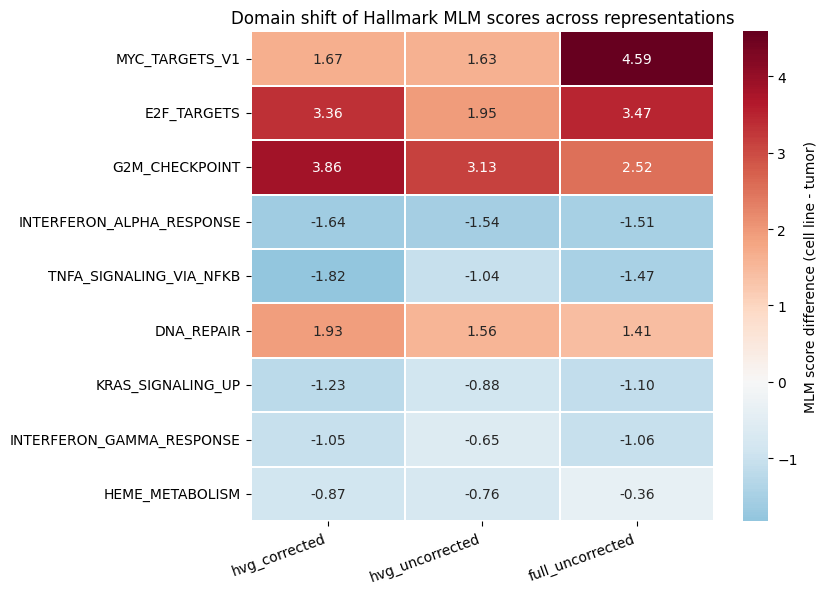

In [8]:
shift_rank_correlation = domain_shift_wide.corr(method="spearman")
display(shift_rank_correlation.round(3))

selected_pathways = set()
for label in REPRESENTATION_LABELS:
    table = domain_shift_by_representation[label]
    selected_pathways.update(table.head(4).index)
    selected_pathways.update(table.tail(4).index)
selected_pathways = sorted(
    selected_pathways,
    key=lambda pathway: -abs(domain_shift_wide.loc[pathway, "full_uncorrected"]),
)

fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(selected_pathways) + 2))
sns.heatmap(
    domain_shift_wide.loc[selected_pathways],
    ax=ax,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    cbar_kws={"label": "MLM score difference (cell line - tumor)"},
)
ax.set_title("Domain shift of Hallmark MLM scores across representations")
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
fig.savefig(FIG_DIR / "mlm_domain_shift_representations.png", dpi=300, bbox_inches="tight")
plt.show()

# Concordance

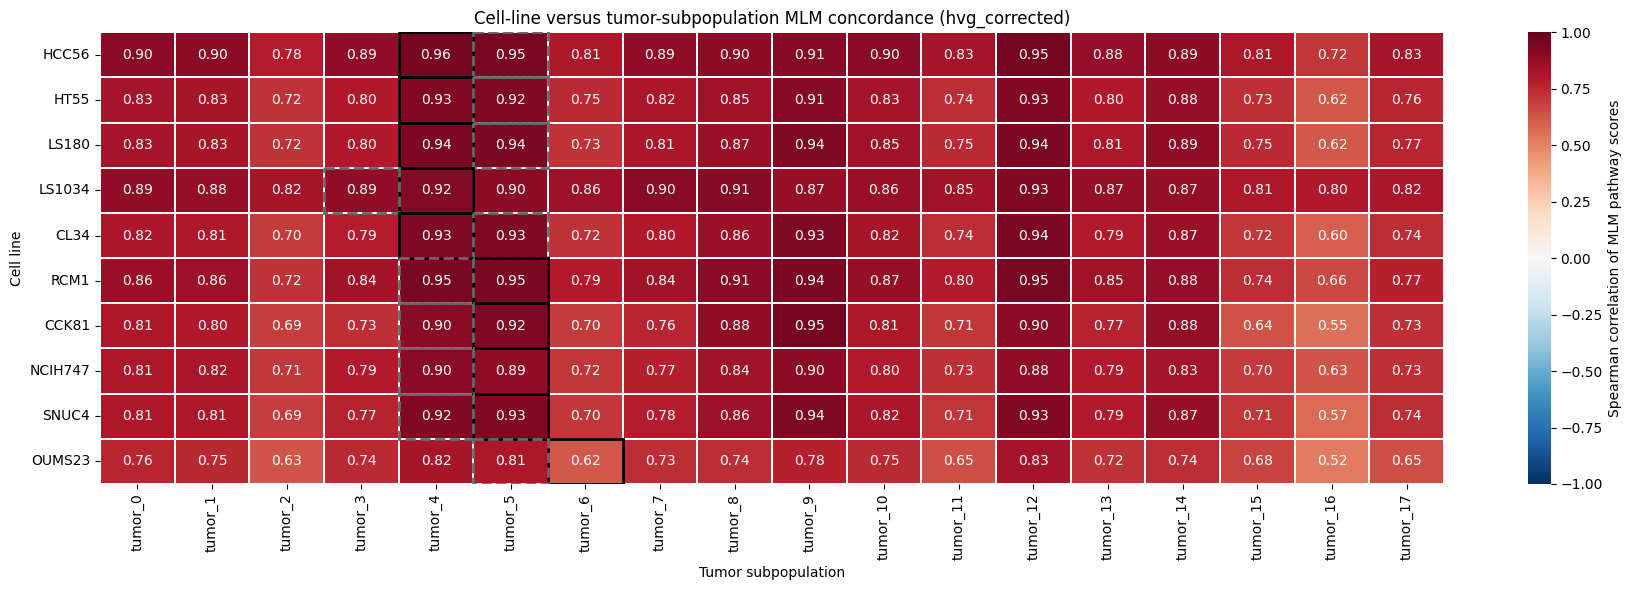

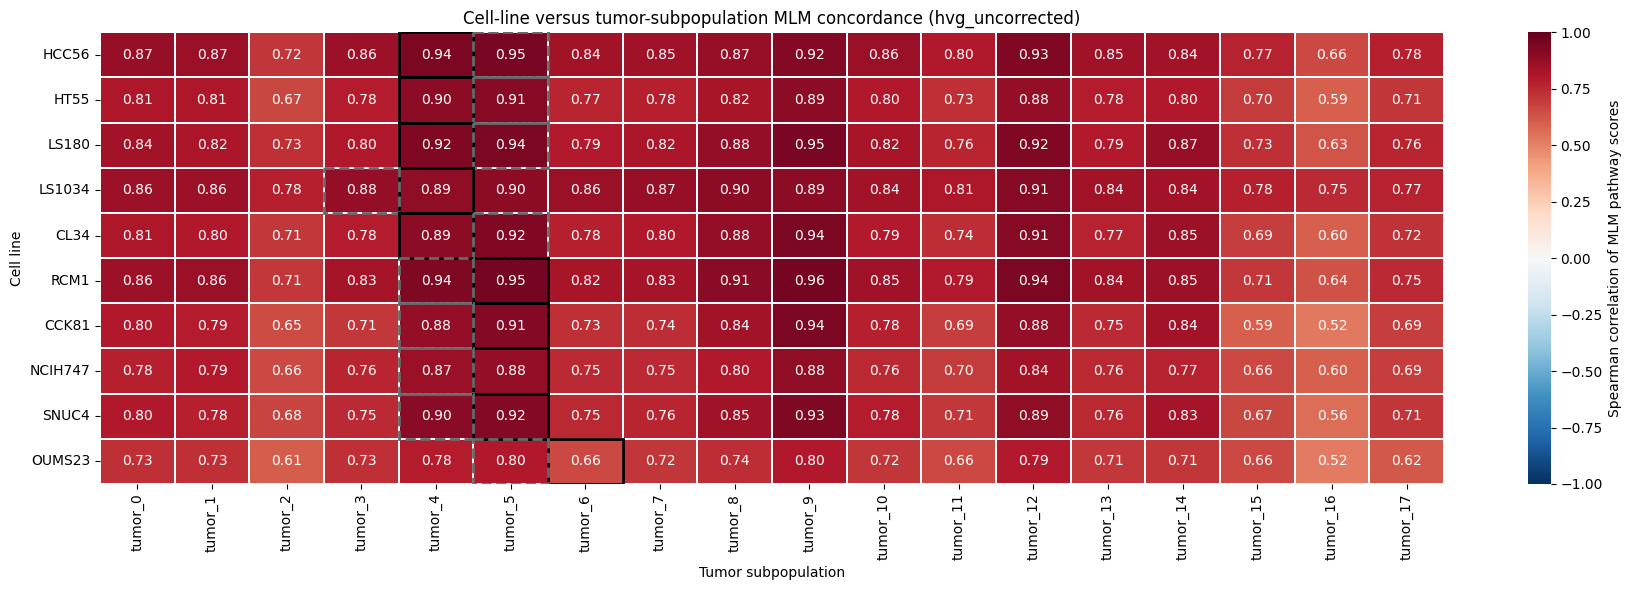

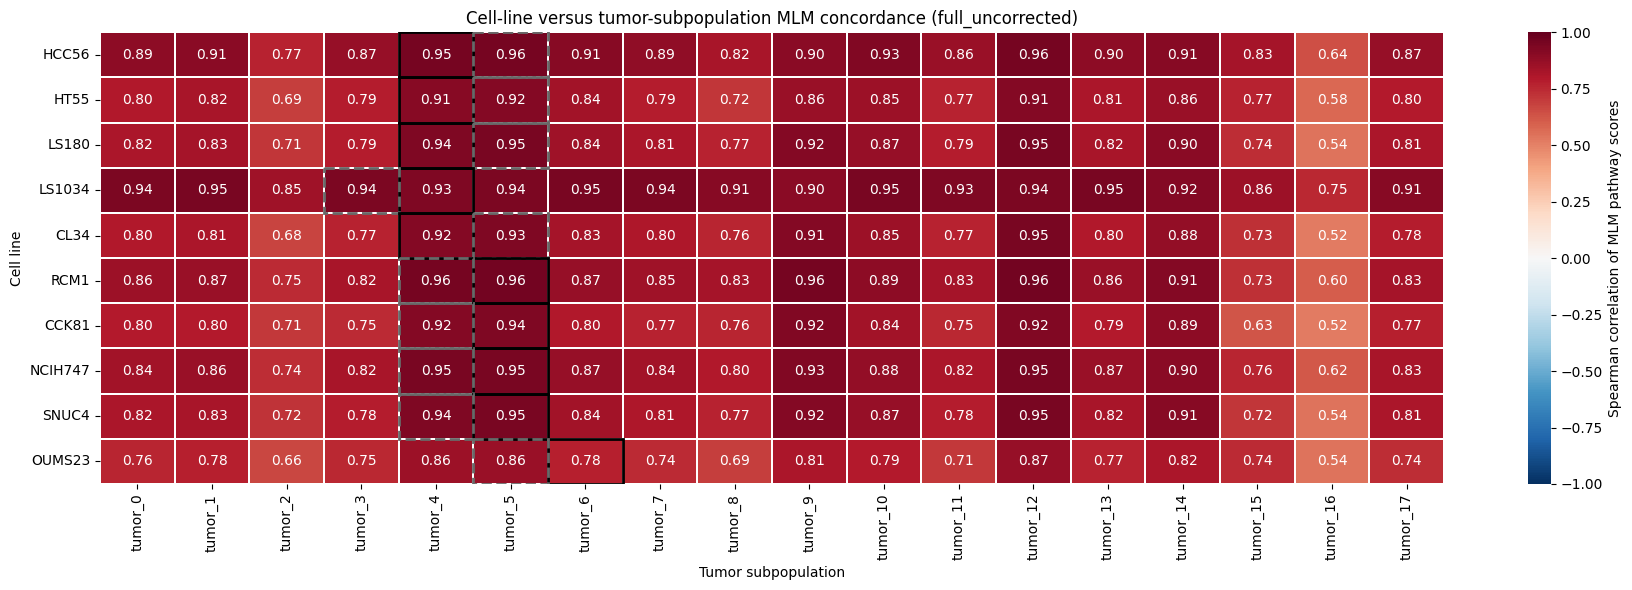

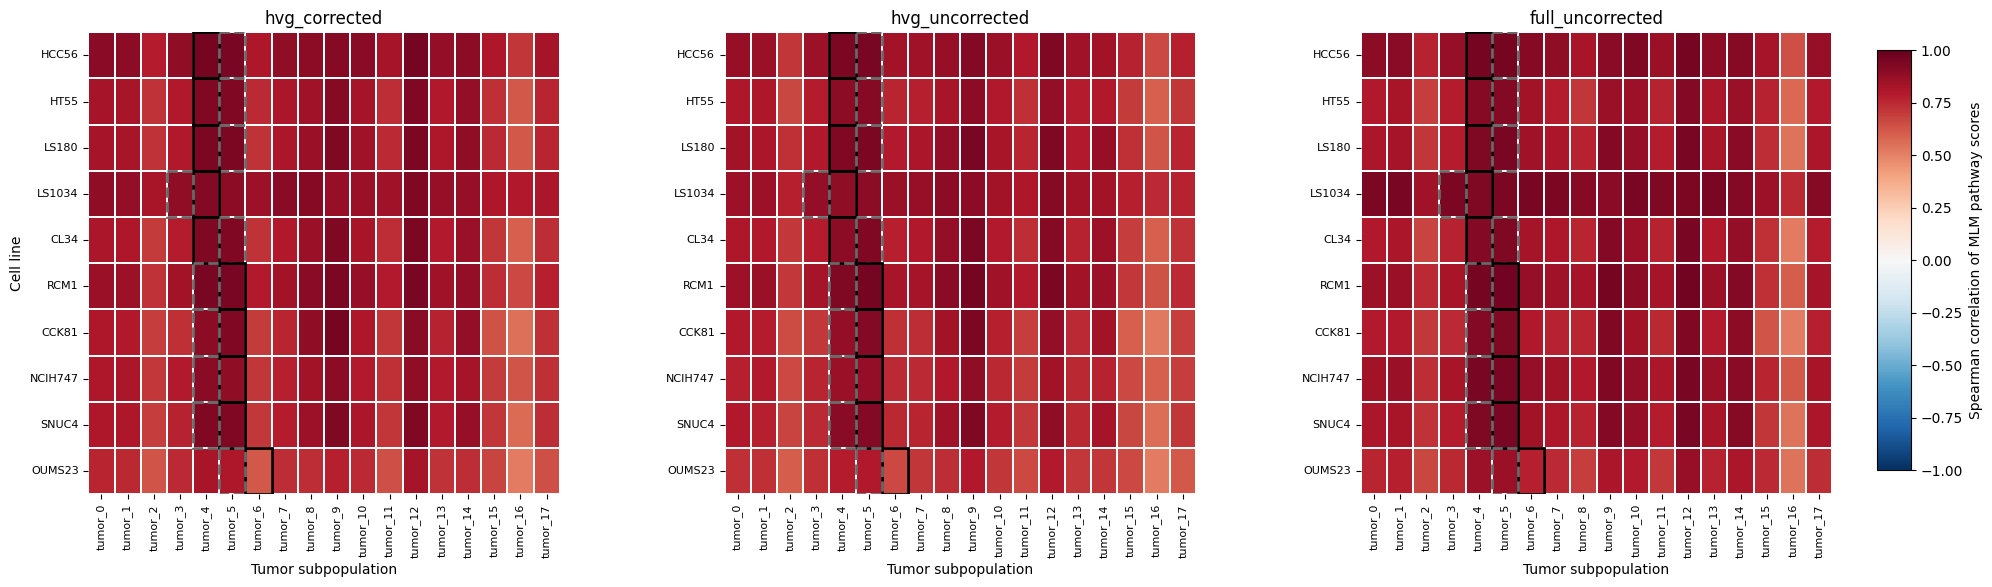

In [9]:
def group_score_matrix(scores, obs, domain, strip_prefix):
    table = scores.join(obs[["domain", "group"]])
    medians = (
        table.loc[table["domain"].eq(domain)]
        .groupby("group", observed=True)[scores.columns]
        .median()
    )
    if strip_prefix:
        medians.index = medians.index.str.replace("^line_", "", regex=True)
    return medians


def concordance_matrix(scores, obs):
    cell_medians = group_score_matrix(scores, obs, "cell_line", strip_prefix=True).reindex(LINE_ORDER)
    tumor_medians = group_score_matrix(scores, obs, "tumor", strip_prefix=False).reindex(TUMOR_ORDER)
    matrix = pd.DataFrame(index=LINE_ORDER, columns=TUMOR_ORDER, dtype=float)
    for cell_line in LINE_ORDER:
        for tumor_group in TUMOR_ORDER:
            matrix.loc[cell_line, tumor_group] = (
                cell_medians.loc[cell_line].corr(tumor_medians.loc[tumor_group], method="spearman")
            )
    return matrix, cell_medians, tumor_medians


concordance_by_representation = {}
for label in REPRESENTATION_LABELS:
    matrix, cell_medians, tumor_medians = concordance_matrix(
        representation_scores[label], representation_obs[label]
    )
    concordance_by_representation[label] = matrix
    matrix.to_csv(MLM_SENS_DIR / f"concordance_{label}.csv")
    cell_medians.to_csv(MLM_SENS_DIR / f"group_medians_cell_line_{label}.csv")
    tumor_medians.to_csv(MLM_SENS_DIR / f"group_medians_tumor_{label}.csv")


def add_match_boxes(ax, matrix):
    for y, cell_line in enumerate(matrix.index):
        for group, color, linestyle in [
            (line_matches.loc[cell_line, "primary_match"], "black", "-"),
            (line_matches.loc[cell_line, "second_match"], "dimgray", "--"),
        ]:
            if group in matrix.columns:
                x = matrix.columns.get_loc(group)
                ax.add_patch(
                    Rectangle((x, y), 1, 1, fill=False, edgecolor=color,
                              linewidth=2.0, linestyle=linestyle)
                )


def plot_concordance(matrix, label):
    fig, ax = plt.subplots(figsize=(18, 6))
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt=".2f",
        linewidths=0.3,
        cbar_kws={"label": "Spearman correlation of MLM pathway scores"},
    )
    add_match_boxes(ax, matrix)
    ax.set_title(f"Cell-line versus tumor-subpopulation MLM concordance ({label})")
    ax.set_xlabel("Tumor subpopulation")
    ax.set_ylabel("Cell line")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"mlm_concordance_{label}.png", dpi=300, bbox_inches="tight")
    plt.show()


for label in REPRESENTATION_LABELS:
    plot_concordance(concordance_by_representation[label], label)

fig, axes = plt.subplots(ncols=len(REPRESENTATION_LABELS), figsize=(7.5 * len(REPRESENTATION_LABELS), 6))
for ax, label in zip(axes, REPRESENTATION_LABELS):
    sns.heatmap(
        concordance_by_representation[label],
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.3,
        cbar=False,
        xticklabels=True,
        yticklabels=True,
    )
    add_match_boxes(ax, concordance_by_representation[label])
    ax.set_title(label)
    ax.set_xlabel("Tumor subpopulation")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)
    ax.set_ylabel("Cell line" if label == REPRESENTATION_LABELS[0] else "")
fig.subplots_adjust(right=0.9, wspace=0.35)
colorbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
shared_colorbar = fig.colorbar(axes[0].collections[0], cax=colorbar_ax)
shared_colorbar.set_label("Spearman correlation of MLM pathway scores")
fig.savefig(FIG_DIR / "mlm_concordance_representations.png", dpi=300, bbox_inches="tight")
plt.show()

## Concordance Metrics

In [10]:
metrics_rows = []
for label in REPRESENTATION_LABELS:
    matrix = concordance_by_representation[label]
    for cell_line in LINE_ORDER:
        primary = str(line_matches.loc[cell_line, "primary_match"])
        runner_up = str(line_matches.loc[cell_line, "second_match"])
        order = matrix.loc[cell_line].sort_values(ascending=False)
        primary_rank = int(order.index.get_loc(primary)) + 1 if primary in order.index else np.nan
        metrics_rows.append({
            "representation": label,
            "cell_line": cell_line,
            "primary_match": primary,
            "runner_up": runner_up,
            "primary_rho": float(matrix.loc[cell_line, primary]),
            "runner_up_rho": float(matrix.loc[cell_line, runner_up]),
            "primary_minus_runner_up": float(
                matrix.loc[cell_line, primary] - matrix.loc[cell_line, runner_up]
            ),
            "primary_rank": primary_rank,
            "primary_top1": primary_rank == 1,
        })

concordance_metrics = pd.DataFrame(metrics_rows)
concordance_metrics.to_csv(MLM_SENS_DIR / "concordance_metrics.csv", index=False)

concordance_summary = (
    concordance_metrics
    .groupby("representation", observed=True)
    .agg(
        n_lines=("cell_line", "nunique"),
        n_primary_gt_runner_up=("primary_minus_runner_up", lambda values: int((values > 0).sum())),
        median_primary_rho=("primary_rho", "median"),
        min_primary_rho=("primary_rho", "min"),
        median_runner_up_rho=("runner_up_rho", "median"),
        median_primary_minus_runner_up=("primary_minus_runner_up", "median"),
        n_primary_top1=("primary_top1", "sum"),
        median_primary_rank=("primary_rank", "median"),
    )
    .reindex(REPRESENTATION_LABELS)
)
display(concordance_summary.round(3))

for label in REPRESENTATION_LABELS:
    values = concordance_by_representation[label].to_numpy(dtype=float).ravel()
    print(f"{label}: line-subpopulation rho min {values.min():.2f}, "
          f"median {np.median(values):.2f}, max {values.max():.2f}")

flattened = pd.DataFrame({
    label: concordance_by_representation[label].to_numpy(dtype=float).ravel()
    for label in REPRESENTATION_LABELS
})
print("Cross-representation Spearman correlation of the 10 x 18 concordance matrices:")
display(flattened.corr(method="spearman").round(3))

,n_lines,n_primary_gt_runner_up,median_primary_rho,min_primary_rho,median_runner_up_rho,median_primary_minus_runner_up,n_primary_top1,median_primary_rank
representation,,,,,,,,
hvg_corrected,10,7,0.928,0.620,0.924,0.004,3,2.0
hvg_uncorrected,10,5,0.906,0.662,0.903,0.004,0,2.0
full_uncorrected,10,3,0.936,0.779,0.938,-0.004,3,3.0


hvg_corrected: line-subpopulation rho min 0.52, median 0.82, max 0.96
hvg_uncorrected: line-subpopulation rho min 0.52, median 0.80, max 0.96
full_uncorrected: line-subpopulation rho min 0.52, median 0.83, max 0.96
Cross-representation Spearman correlation of the 10 x 18 concordance matrices:


,hvg_corrected,hvg_uncorrected,full_uncorrected
hvg_corrected,1.000,0.966,0.856
hvg_uncorrected,0.966,1.000,0.843
full_uncorrected,0.856,0.843,1.000


# MLM/GSEA consistency

In [12]:
GSEA_DIR = DE_DIR / "gsea_hallmark"
gsea_tumor = pd.read_csv(GSEA_DIR / "hallmark_prerank_tumor.csv")

consistency_rows = []
for label in REPRESENTATION_LABELS:
    scores = representation_scores[label]
    obs = representation_obs[label]
    subpops = sorted(obs.loc[obs["domain"].eq("tumor"), "group"].unique(), key=tumor_group_sort_key)

    rows = []
    for subpopulation in subpops:
        source_mask = obs["domain"].eq("tumor") & obs["group"].eq(subpopulation)
        rest_mask = obs["domain"].eq("tumor") & ~obs["group"].eq(subpopulation)
        delta = scores.loc[source_mask].median() - scores.loc[rest_mask].median()
        for pathway, value in delta.items():
            rows.append({"subpopulation": subpopulation, "pathway": pathway, "mlm_delta": value})
    contrasts = pd.DataFrame(rows)

    comparison = contrasts.merge(
        gsea_tumor[["subpopulation", "pathway", "nes", "fdr_qval"]],
        on=["subpopulation", "pathway"],
        how="inner",
    )
    comparison["same_direction"] = np.sign(comparison["mlm_delta"]) == np.sign(comparison["nes"])
    directional_agreement = comparison["same_direction"].mean()
    rank_correlation = (
        comparison[["mlm_delta", "nes"]].corr(method="spearman").loc["mlm_delta", "nes"]
    )
    consistency_rows.append({
        "representation": label,
        "n_comparisons": len(comparison),
        "directional_agreement": directional_agreement,
        "spearman_mlm_gsea": rank_correlation,
    })
    print(f"{label}: {directional_agreement:.1%} directional agreement, "
          f"Spearman {rank_correlation:.3f} over {len(comparison)} comparisons")

mlm_gsea_consistency = (
    pd.DataFrame(consistency_rows).set_index("representation").reindex(REPRESENTATION_LABELS)
)
mlm_gsea_consistency.to_csv(MLM_SENS_DIR / "mlm_gsea_consistency.csv")
display(mlm_gsea_consistency.round(3))

hvg_corrected: 72.8% directional agreement, Spearman 0.642 over 810 comparisons
hvg_uncorrected: 68.0% directional agreement, Spearman 0.517 over 810 comparisons
full_uncorrected: 68.3% directional agreement, Spearman 0.496 over 810 comparisons


,n_comparisons,directional_agreement,spearman_mlm_gsea
representation,,,
hvg_corrected,810,0.728,0.642
hvg_uncorrected,810,0.680,0.517
full_uncorrected,810,0.683,0.496


# Summary

In [13]:
n_genes_by_representation = {
    "hvg_corrected": int(corrected_expression.n_vars),
    "hvg_uncorrected": len(hvg_hallmark_genes),
    "full_uncorrected": int(full_manifest["n_genes"]),
}

summary_rows = []
for label in REPRESENTATION_LABELS:
    metrics = concordance_metrics.loc[concordance_metrics["representation"].eq(label)]
    consistency = mlm_gsea_consistency.loc[label]
    shift_correlation = float(shift_rank_correlation.loc[label, "full_uncorrected"])
    summary_rows.append({
        "representation": label,
        "n_genes": n_genes_by_representation[label],
        "n_pathways": len(SHARED_PATHWAYS),
        "domain_shift_spearman_vs_full": shift_correlation,
        "min_line_subpop_rho": float(np.nanmin(concordance_by_representation[label].to_numpy())),
        "median_line_subpop_rho": float(np.nanmedian(concordance_by_representation[label].to_numpy())),
        "n_lines_primary_gt_runner_up": int((metrics["primary_minus_runner_up"] > 0).sum()),
        "median_primary_minus_runner_up": float(metrics["primary_minus_runner_up"].median()),
        "mlm_gsea_directional_agreement": float(consistency["directional_agreement"]),
        "mlm_gsea_spearman": float(consistency["spearman_mlm_gsea"]),
    })

summary_representations = (
    pd.DataFrame(summary_rows).set_index("representation").reindex(REPRESENTATION_LABELS)
)
summary_representations.to_csv(MLM_SENS_DIR / "summary_representations.csv")
display(summary_representations.round(3))

print("Saved artifacts:")
for path in sorted(MLM_SENS_DIR.glob("*")):
    print(" ", path.name)

,n_genes,n_pathways,domain_shift_spearman_vs_full,min_line_subpop_rho,median_line_subpop_rho,n_lines_primary_gt_runner_up,median_primary_minus_runner_up,mlm_gsea_directional_agreement,mlm_gsea_spearman
representation,,,,,,,,,
hvg_corrected,1135,45,0.724,0.519,0.816,7,0.004,0.728,0.642
hvg_uncorrected,1135,45,0.647,0.521,0.798,5,0.004,0.680,0.517
full_uncorrected,4237,45,1.000,0.516,0.834,3,-0.004,0.683,0.496


Saved artifacts:
  concordance_full_uncorrected.csv
  concordance_hvg_corrected.csv
  concordance_hvg_uncorrected.csv
  concordance_metrics.csv
  domain_shift_full_uncorrected.csv
  domain_shift_full_uncorrected_all50.csv
  domain_shift_hvg_corrected.csv
  domain_shift_hvg_uncorrected.csv
  domain_shift_representations.csv
  group_medians_cell_line_full_uncorrected.csv
  group_medians_cell_line_hvg_corrected.csv
  group_medians_cell_line_hvg_uncorrected.csv
  group_medians_tumor_full_uncorrected.csv
  group_medians_tumor_hvg_corrected.csv
  group_medians_tumor_hvg_uncorrected.csv
  manifest_hvg_corrected.json
  manifest_hvg_uncorrected.json
  mlm_gsea_consistency.csv
  mlm_scores_hvg_corrected.h5ad
  mlm_scores_hvg_uncorrected.h5ad
  scanvi_normalized_expression_hvg_hallmark.h5ad
  scanvi_normalized_expression_hvg_hallmark_manifest.json
  summary_representations.csv
